<a href="https://colab.research.google.com/github/BarGinger/Deep_Learning_MEG/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning - Assigment 2

### Group Number: 22

### Teammates:
1. **Mahshid Jafar Tajrishi**
2. **Bar Melinarskiy**
3. **Cis van Aken**
4. **Simon van Klompenburg**

## Imports entire notebook

In [1]:
# Helper function to check if the code is running in Google Colab
def is_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False

# Usage
if is_colab():
    print("Running in Google Colab")
else:
    print("Not running in Google Colab")


# Importing libraries
import pandas as pd
import numpy as np
import Models
import utils as utils
import torch
import matplotlib.pyplot as plt
import os
import random
import datetime
import importlib
importlib.reload(utils)
importlib.reload(Models)
from Model import MEGClassifier, MultiviewAttention

Not running in Google Colab


## Global Definitions

In [ ]:
# Path to the zip file
data_dir = "./Data"
google_drive_folder = "/content/drive/MyDrive/UU"
zip_path = f"{data_dir}/Final Project data.zip"
output_dir = "./Output"
model_dir = "./Models"

# check if outpiut directory exists
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# check if model directory exists
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Set the device to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

debug_mode = False

# Set pandas display options to show all columns
pd.set_option('display.max_columns', None)

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# model and data related parameters
scaler_type = utils.NormalizationType.Z_SCORE_LOCAL  # or MINMAX_LOCAL, Z_SCORE_TIMEWISE
which_dataset = "cross"  # or "cross"
downsample = True  # or False
downsample_rate = 0  
if downsample:
    downsample_rate = 9

### Check if we are in google colab then we need to mount the drive

In [3]:
# If we are in colab and we need to mount the drive
if is_colab():
  from google.colab import drive
  # Mount Google Drive
  drive.mount('/content/drive')
  print("Google Drive mounted successfully.")
  data_dir = f"{google_drive_folder}/Final Project data"
else:
  print("Not in Google Colab.")

Not in Google Colab.


### Check if we have cude

In [4]:
# Check if CUDA is available
print(torch.__version__)
print(torch.version.cuda)  # Should match CUDA 12.5
print(torch.backends.cudnn.version())  # Should return a version, not None
print(torch.cuda.is_available())  # Should return True

2.5.1
None
90100
True


### Extract the Zip File

In [5]:
import zipfile

# Check if the dataset is already extracted, if not extract it
if not os.path.exists(data_dir):
    print("Extracting the dataset...")
    #unzip
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(data_dir)
    #list files in the extracted dir
    os.listdir(data_dir)
else:
    print("Dataset already extracted.")

Dataset already extracted.


### Load one example

Matrix shape: (248, 35624)


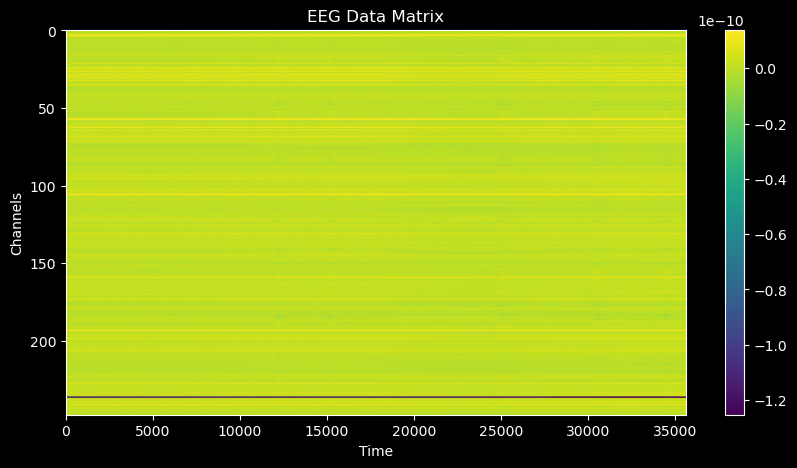

In [6]:
## peak into a matrix to see the data
matrix = utils.get_dataset_from_h5py(f"{data_dir}/Intra/train/task_working_memory_105923_3.h5")
if matrix is not None:
    print(f"Matrix shape: {matrix.shape}")


# plot that matrix
plt.figure(figsize=(10, 5))
plt.imshow(matrix, aspect='auto', cmap='viridis')
plt.colorbar()
plt.title("EEG Data Matrix")
plt.xlabel("Time")
plt.ylabel("Channels")
plt.show()

### Load the datasets

In [7]:
## load the chosen dataset/s
print(f"Loading {which_dataset} dataset...")
if which_dataset == "intra":
    # INTRA TRAIN
    intra_train_data_scaled, intra_train_df = utils.try_load_scaled("intra_train", scaler_type)
    if intra_train_data_scaled is None:
        intra_train_folder = os.path.join(data_dir, "Intra", "train")
        intra_train_data, intra_train_df = utils.load_eeg_data_and_metadata(intra_train_folder, split="train")
        intra_train_data_scaled, intra_train_df = utils.scale_and_cache(
            intra_train_data, intra_train_df, "intra_train", scaler_type, downsample_factor=downsample_rate)

    # INTRA TEST
    intra_test_data_scaled, intra_test_df = utils.try_load_scaled("intra_test", scaler_type)
    if intra_test_data_scaled is None:
        intra_test_folder = os.path.join(data_dir, "Intra", "test")
        intra_test_data, intra_test_df = utils.load_eeg_data_and_metadata(intra_test_folder, split="test")
        intra_test_data_scaled, intra_test_df = utils.scale_and_cache(
            intra_test_data, intra_test_df, "intra_test", scaler_type, downsample_factor=downsample_rate)
        
if which_dataset == "cross":
    # CROSS TRAIN
    cross_train_data_scaled, cross_train_df = utils.try_load_scaled("cross_train", scaler_type)
    if cross_train_data_scaled is None:
        cross_train_folder = os.path.join(data_dir, "Cross", "train")
        cross_train_data, cross_train_df = utils.load_eeg_data_and_metadata(cross_train_folder, split="train")
        cross_train_data_scaled, cross_train_df = utils.scale_and_cache(
            cross_train_data, cross_train_df, "cross_train", scaler_type, downsample_factor=downsample_rate)

    # CROSS TEST (list of datasets)
    cross_test_data_scaled = []
    cross_test_df_list = []
    for i in range(1, 4):
        prefix = f"cross_test{i}"
        scaled, meta = utils.try_load_scaled(prefix, scaler_type)
        if scaled is None:
            folder = os.path.join(data_dir, "Cross", f"test{i}")
            data, df = utils.load_eeg_data_and_metadata(folder, split=f"test{i}")
            scaled, meta = utils.scale_and_cache(data, df, prefix, scaler_type, downsample_factor=downsample_rate)
        cross_test_data_scaled.append(scaled)
        cross_test_df_list.append(meta)

print(f"Data for dataset {which_dataset} was loaded successfully")

Loading cross dataset...
Loading cached: Data\Normalized\z_score_local\cross_train_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test1_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test2_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test3_scaled.pt
Data for dataset cross was loaded successfully


### Merge the cross dfs and tensors 

In [8]:
import pandas as pd
import torch

cross_test_df_merged = pd.concat(cross_test_df_list, ignore_index=True)
cross_test_data_merged = torch.cat(cross_test_data_scaled, dim=0)
print(cross_test_data_merged.shape)


# Display the first 50 rows of the merged DataFrame
cross_test_df_merged.head(50)

torch.Size([48, 248, 3958])


,filename,dataset_name,patient_id,trial,split,task_type,prefix,scaler_type,downsampled,downsample_factor,task_type_cat
0,rest_162935_1.h5,rest,162935,1,test1,rest,cross_test1,z_score_local,True,9,0
1,rest_162935_10.h5,rest,162935,10,test1,rest,cross_test1,z_score_local,True,9,0
2,rest_162935_3.h5,rest,162935,3,test1,rest,cross_test1,z_score_local,True,9,0
3,rest_162935_5.h5,rest,162935,5,test1,rest,cross_test1,z_score_local,True,9,0
4,task_motor_162935_1.h5,task_motor,162935,1,test1,task_motor,cross_test1,z_score_local,True,9,1
5,task_motor_162935_3.h5,task_motor,162935,3,test1,task_motor,cross_test1,z_score_local,True,9,1
6,task_motor_162935_4.h5,task_motor,162935,4,test1,task_motor,cross_test1,z_score_local,True,9,1
7,task_motor_162935_9.h5,task_motor,162935,9,test1,task_motor,cross_test1,z_score_local,True,9,1
8,task_story_math_162935_2.h5,task_story_math,162935,2,test1,task_story_math,cross_test1,z_score_local,True,9,2
9,task_story_math_162935_3.h5,task_story_math,162935,3,test1,task_story_math,cross_test1,z_score_local,True,9,2


### Definitions for training and logging

In [9]:
# Choose which dataset to train on:
if which_dataset == "intra":
    train_data, train_df = intra_train_data_scaled, intra_train_df
    test_data, test_df = intra_test_data_scaled, intra_test_df
else: # cross
    train_data, train_df = cross_train_data_scaled, cross_train_df
    test_data, test_df = cross_test_data_merged, cross_test_df_merged

print("train task types counts:")
print(np.bincount(train_df['task_type'].astype('category').cat.codes))
print("test task types counts:")
print(np.bincount(test_df['task_type'].astype('category').cat.codes))


timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
# Set this once at the top of your notebook/cell
MODEL_NAME = utils.ModelClass.__name__ # "MEGClassifier"
print(f"Using model class: {MODEL_NAME}")
model_name = f"{MODEL_NAME}_{which_dataset}"
model_pth_path = f"{model_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.pth"
model_csv_path = f"{output_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.csv"
model_json_path = f"{model_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.json"
best_model = None

# create folders if they do not exist
if not os.path.exists(f"{model_dir}/{which_dataset}"):
    os.makedirs(f"{model_dir}/{which_dataset}")


if not os.path.exists(f"{output_dir}/{which_dataset}"):
    os.makedirs(f"{output_dir}/{which_dataset}")

train task types counts:
[16 16 16 16]
test task types counts:
[12 12 12 12]
Using model class: MultiviewAttention


### Training stage #1 - fine-tuning using cross validation and optuna

[I 2025-05-29 21:31:44,157] A new study created in memory with name: no-name-6729492b-7760-49e4-b3d1-787c90c8c76b
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (7, 7) which is of type tuple.
  warnings.warn(message)


Trial: 1, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

c:\Users\bar24\OneDrive - Universiteit Utrecht\Documents\School\UU Data Sceince MSc\1st Year\Period 4\Deep learning (INFOMDLR)\Assignments\Deep_Learning_MEG\utils.py:640: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_metrics_df = pd.concat([all_metrics_df, pd.DataFrame([row])], ignore_index=True)


Early stopping triggered after 8 epochs (no val_loss improvement).


Trial: 1, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 6 epochs (no val_loss improvement).


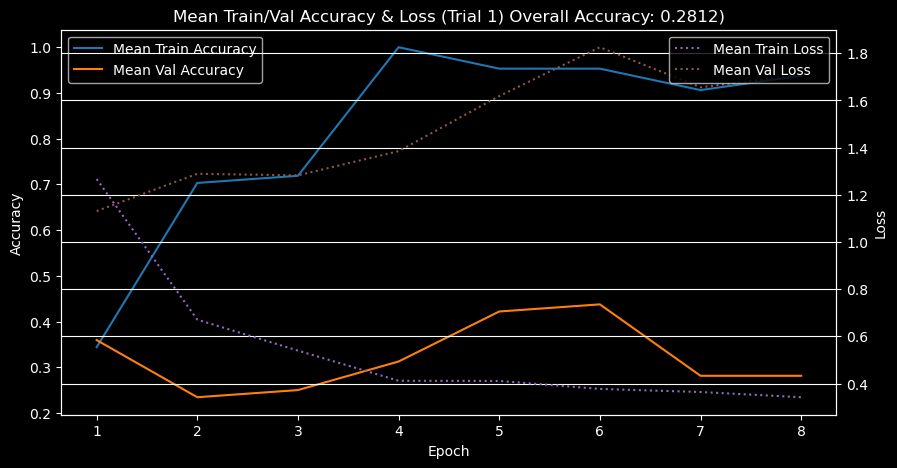

[I 2025-05-29 21:31:57,497] Trial 0 finished with value: 0.359375 and parameters: {'window_size': 16, 'mesh_rows_index': 0, 'conv1_filters': 16, 'conv2_filters': 256, 'conv3_filters': 64, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (7, 7), 'padding1': 2, 'padding2': 2, 'padding3': 3, 'conv1_activation': 'relu', 'conv2_activation': 'relu', 'conv3_activation': 'leaky_relu', 'dense_nodes': 128, 'dense_activation': 'elu', 'depth': 248, 'lstm1_cells': 256, 'lstm2_cells': 256, 'dense3_nodes': 128, 'dense3_activation': 'gelu', 'learning_rate': 0.0008300467245625272, 'batch_size': 64, 'dropout_rate': 0.2, 'optimizer': 'rmsprop', 'weight_decay': 0.003095629779903907, 'label_smoothing': 0.05, 'transformer_nhead': 2, 'transformer_layers': 1}. Best is trial 0 with value: 0.359375.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, f

Trial: 2, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 8 epochs (no val_loss improvement).


Trial: 2, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 17 epochs (no val_loss improvement).


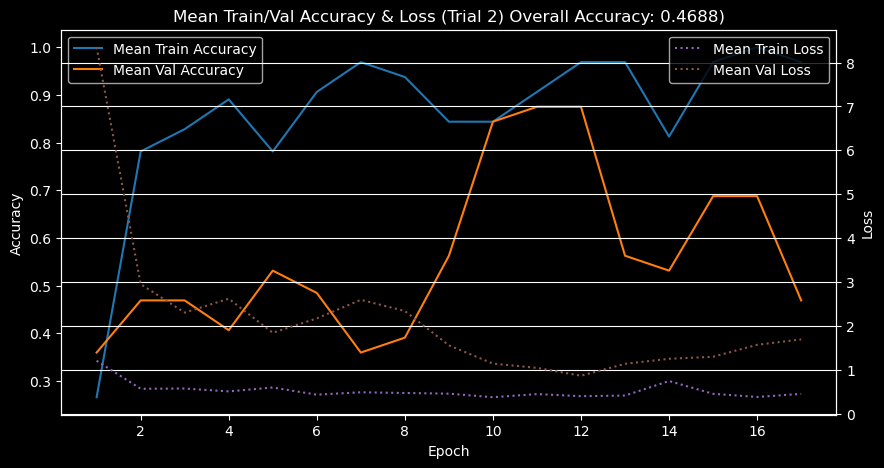

[I 2025-05-29 21:32:23,490] Trial 1 finished with value: 0.53125 and parameters: {'window_size': 8, 'mesh_rows_index': 0, 'conv1_filters': 128, 'conv2_filters': 256, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (7, 7), 'conv3_kernel_shape': (3, 3), 'padding1': 3, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'gelu', 'conv2_activation': 'elu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'gelu', 'depth': 248, 'lstm1_cells': 128, 'lstm2_cells': 32, 'dense3_nodes': 256, 'dense3_activation': 'relu', 'learning_rate': 0.0008306914652738282, 'batch_size': 8, 'dropout_rate': 0.3, 'optimizer': 'adam', 'weight_decay': 3.6649070260984194e-08, 'label_smoothing': 0.05, 'transformer_nhead': 4, 'transformer_layers': 1}. Best is trial 1 with value: 0.53125.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and s

Trial: 3, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 18 epochs (no val_loss improvement).


Trial: 3, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 18 epochs (no val_loss improvement).


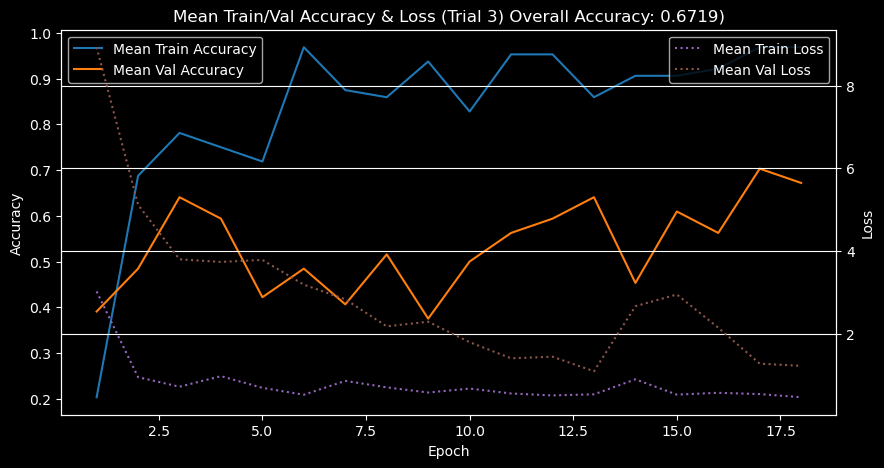

[I 2025-05-29 21:32:41,020] Trial 2 finished with value: 0.640625 and parameters: {'window_size': 4, 'mesh_rows_index': 1, 'conv1_filters': 16, 'conv2_filters': 128, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (7, 7), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 1, 'padding3': 2, 'conv1_activation': 'elu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'leaky_relu', 'depth': 248, 'lstm1_cells': 32, 'lstm2_cells': 256, 'dense3_nodes': 32, 'dense3_activation': 'gelu', 'learning_rate': 0.004163758322977153, 'batch_size': 8, 'dropout_rate': 0.15000000000000002, 'optimizer': 'rmsprop', 'weight_decay': 0.00020390156741294013, 'label_smoothing': 0.0, 'transformer_nhead': 2, 'transformer_layers': 1}. Best is trial 2 with value: 0.640625.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of

Trial: 4, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 8 epochs (no val_loss improvement).


Trial: 4, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 7 epochs (no val_loss improvement).


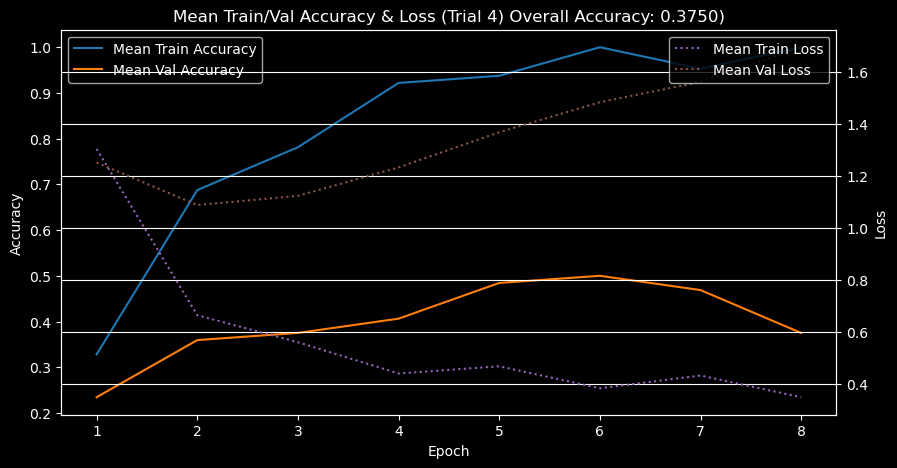

[I 2025-05-29 21:32:47,893] Trial 3 finished with value: 0.359375 and parameters: {'window_size': 4, 'mesh_rows_index': 1, 'conv1_filters': 16, 'conv2_filters': 256, 'conv3_filters': 128, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 0, 'padding3': 2, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'gelu', 'dense_nodes': 32, 'dense_activation': 'relu', 'depth': 248, 'lstm1_cells': 256, 'lstm2_cells': 32, 'dense3_nodes': 32, 'dense3_activation': 'leaky_relu', 'learning_rate': 0.000876406521957616, 'batch_size': 16, 'dropout_rate': 0.15000000000000002, 'optimizer': 'adamw', 'weight_decay': 0.00034586422740401433, 'label_smoothing': 0.2, 'transformer_nhead': 2, 'transformer_layers': 1}. Best is trial 2 with value: 0.640625.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tup

Trial: 5, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 15 epochs (no val_loss improvement).


Trial: 5, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 31 epochs (no val_loss improvement).


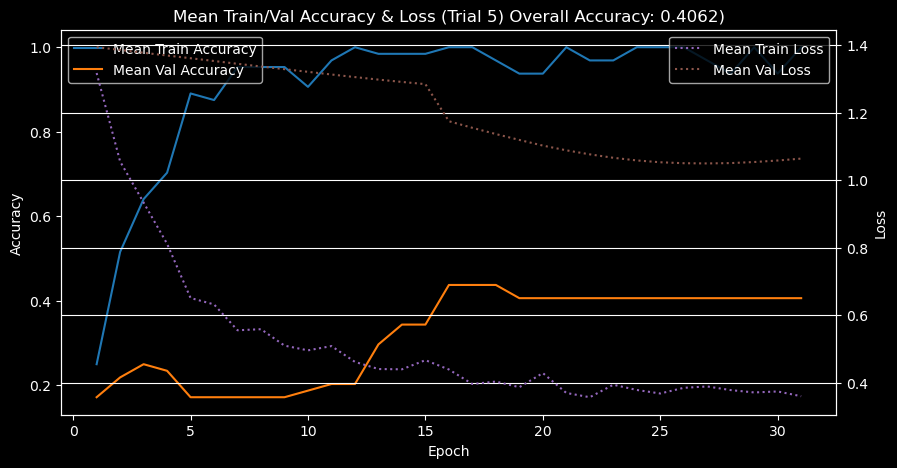

[I 2025-05-29 21:33:08,449] Trial 4 finished with value: 0.328125 and parameters: {'window_size': 16, 'mesh_rows_index': 1, 'conv1_filters': 32, 'conv2_filters': 64, 'conv3_filters': 64, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (7, 7), 'conv3_kernel_shape': (3, 3), 'padding1': 0, 'padding2': 1, 'padding3': 0, 'conv1_activation': 'elu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'gelu', 'dense_nodes': 32, 'dense_activation': 'elu', 'depth': 248, 'lstm1_cells': 64, 'lstm2_cells': 32, 'dense3_nodes': 32, 'dense3_activation': 'leaky_relu', 'learning_rate': 3.5752638825528845e-05, 'batch_size': 64, 'dropout_rate': 0.35000000000000003, 'optimizer': 'adamw', 'weight_decay': 1.317172716283315e-07, 'label_smoothing': 0.2, 'transformer_nhead': 8, 'transformer_layers': 2}. Best is trial 2 with value: 0.640625.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of Non

Trial: 6, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 8 epochs (no val_loss improvement).


Trial: 6, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 10 epochs (no val_loss improvement).


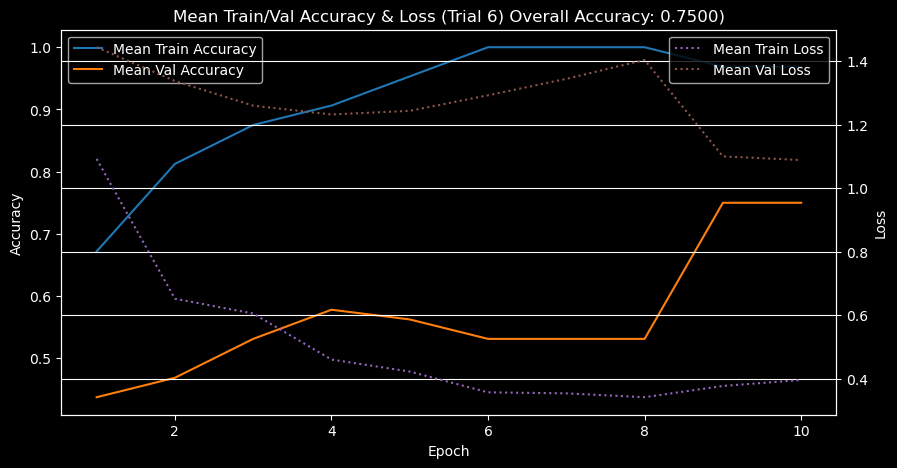

[I 2025-05-29 21:33:24,080] Trial 5 finished with value: 0.515625 and parameters: {'window_size': 16, 'mesh_rows_index': 0, 'conv1_filters': 64, 'conv2_filters': 32, 'conv3_filters': 128, 'conv1_kernel_shape': (7, 7), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 1, 'padding2': 0, 'padding3': 2, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'leaky_relu', 'dense_nodes': 32, 'dense_activation': 'relu', 'depth': 248, 'lstm1_cells': 256, 'lstm2_cells': 128, 'dense3_nodes': 256, 'dense3_activation': 'relu', 'learning_rate': 0.00012899401340782195, 'batch_size': 8, 'dropout_rate': 0.05, 'optimizer': 'adamw', 'weight_decay': 8.629333879589639e-05, 'label_smoothing': 0.05, 'transformer_nhead': 4, 'transformer_layers': 1}. Best is trial 2 with value: 0.640625.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, 

Trial: 7, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 8 epochs (no val_loss improvement).


Trial: 7, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 8 epochs (no val_loss improvement).


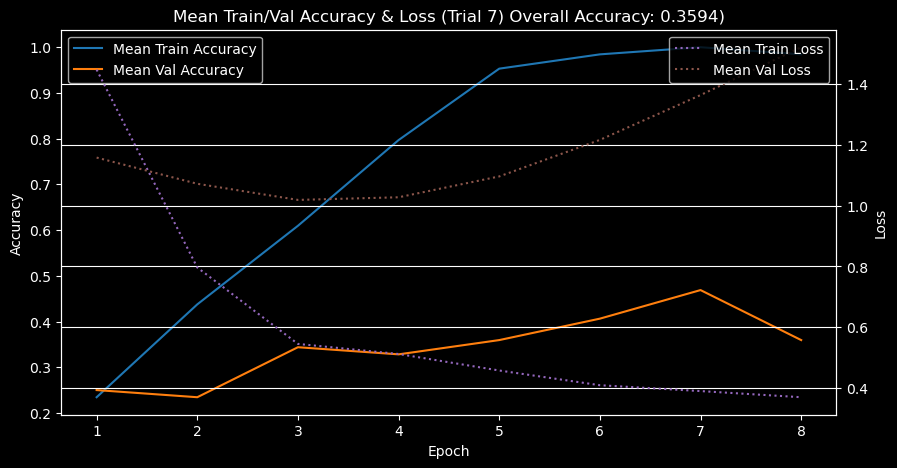

[I 2025-05-29 21:33:35,065] Trial 6 finished with value: 0.34375 and parameters: {'window_size': 16, 'mesh_rows_index': 0, 'conv1_filters': 16, 'conv2_filters': 64, 'conv3_filters': 128, 'conv1_kernel_shape': (7, 7), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 3, 'padding3': 3, 'conv1_activation': 'relu', 'conv2_activation': 'relu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'elu', 'depth': 248, 'lstm1_cells': 128, 'lstm2_cells': 128, 'dense3_nodes': 256, 'dense3_activation': 'leaky_relu', 'learning_rate': 0.000462693553641127, 'batch_size': 32, 'dropout_rate': 0.4, 'optimizer': 'adam', 'weight_decay': 4.5002263312877704e-07, 'label_smoothing': 0.1, 'transformer_nhead': 4, 'transformer_layers': 2}. Best is trial 2 with value: 0.640625.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float

Trial: 8, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 7 epochs (no val_loss improvement).


Trial: 8, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 6 epochs (no val_loss improvement).


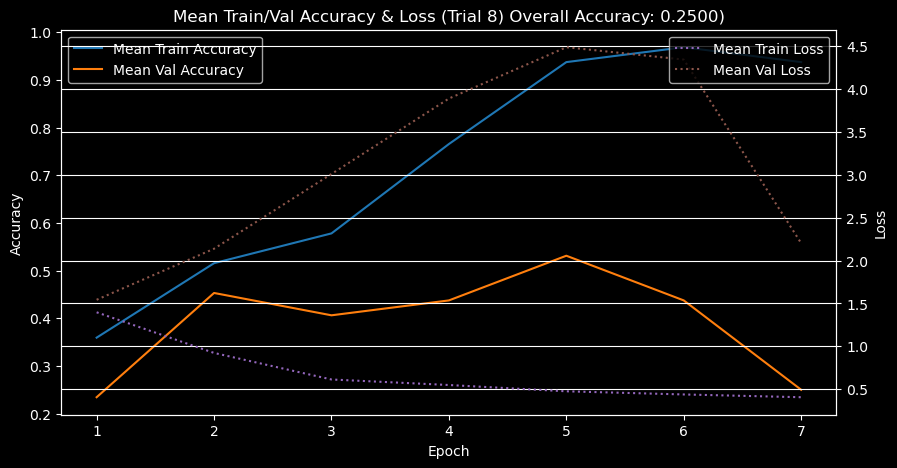

[I 2025-05-29 21:33:44,885] Trial 7 finished with value: 0.359375 and parameters: {'window_size': 8, 'mesh_rows_index': 1, 'conv1_filters': 64, 'conv2_filters': 128, 'conv3_filters': 128, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (7, 7), 'conv3_kernel_shape': (7, 7), 'padding1': 3, 'padding2': 1, 'padding3': 3, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'relu', 'conv3_activation': 'elu', 'dense_nodes': 128, 'dense_activation': 'relu', 'depth': 248, 'lstm1_cells': 64, 'lstm2_cells': 64, 'dense3_nodes': 128, 'dense3_activation': 'elu', 'learning_rate': 0.0013659231744475087, 'batch_size': 16, 'dropout_rate': 0.35000000000000003, 'optimizer': 'adamw', 'weight_decay': 7.960634246622655e-08, 'label_smoothing': 0.05, 'transformer_nhead': 4, 'transformer_layers': 2}. Best is trial 2 with value: 0.640625.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, 

Trial: 9, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 7 epochs (no val_loss improvement).


Trial: 9, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 10 epochs (no val_loss improvement).


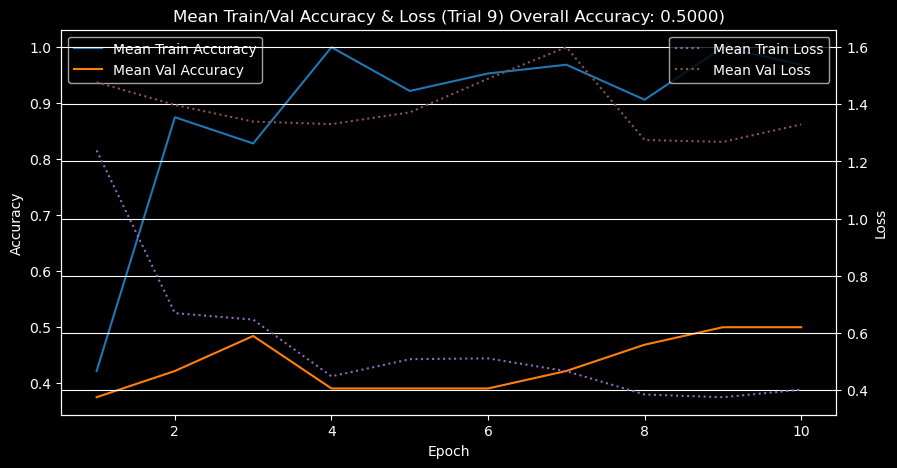

[I 2025-05-29 21:34:02,218] Trial 8 finished with value: 0.46875 and parameters: {'window_size': 16, 'mesh_rows_index': 1, 'conv1_filters': 128, 'conv2_filters': 128, 'conv3_filters': 64, 'conv1_kernel_shape': (7, 7), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (5, 5), 'padding1': 1, 'padding2': 3, 'padding3': 2, 'conv1_activation': 'relu', 'conv2_activation': 'relu', 'conv3_activation': 'elu', 'dense_nodes': 32, 'dense_activation': 'relu', 'depth': 248, 'lstm1_cells': 256, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'gelu', 'learning_rate': 3.143593699954221e-05, 'batch_size': 8, 'dropout_rate': 0.2, 'optimizer': 'rmsprop', 'weight_decay': 0.001037689964333811, 'label_smoothing': 0.1, 'transformer_nhead': 2, 'transformer_layers': 2}. Best is trial 2 with value: 0.640625.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and s

Trial: 10, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 7 epochs (no val_loss improvement).


Trial: 10, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 6 epochs (no val_loss improvement).


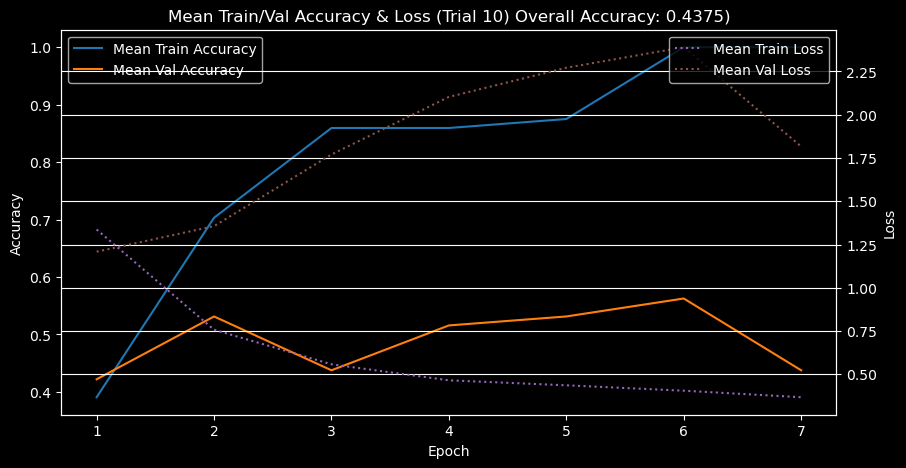

[I 2025-05-29 21:34:11,480] Trial 9 finished with value: 0.546875 and parameters: {'window_size': 4, 'mesh_rows_index': 0, 'conv1_filters': 16, 'conv2_filters': 256, 'conv3_filters': 256, 'conv1_kernel_shape': (7, 7), 'conv2_kernel_shape': (7, 7), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 2, 'padding3': 3, 'conv1_activation': 'elu', 'conv2_activation': 'relu', 'conv3_activation': 'leaky_relu', 'dense_nodes': 64, 'dense_activation': 'gelu', 'depth': 248, 'lstm1_cells': 32, 'lstm2_cells': 256, 'dense3_nodes': 256, 'dense3_activation': 'gelu', 'learning_rate': 0.0004069602349282693, 'batch_size': 16, 'dropout_rate': 0.15000000000000002, 'optimizer': 'adamw', 'weight_decay': 0.00016875990863818465, 'label_smoothing': 0.0, 'transformer_nhead': 2, 'transformer_layers': 1}. Best is trial 2 with value: 0.640625.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None,

Trial: 11, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 12 epochs (no val_loss improvement).


Trial: 11, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 8 epochs (no val_loss improvement).


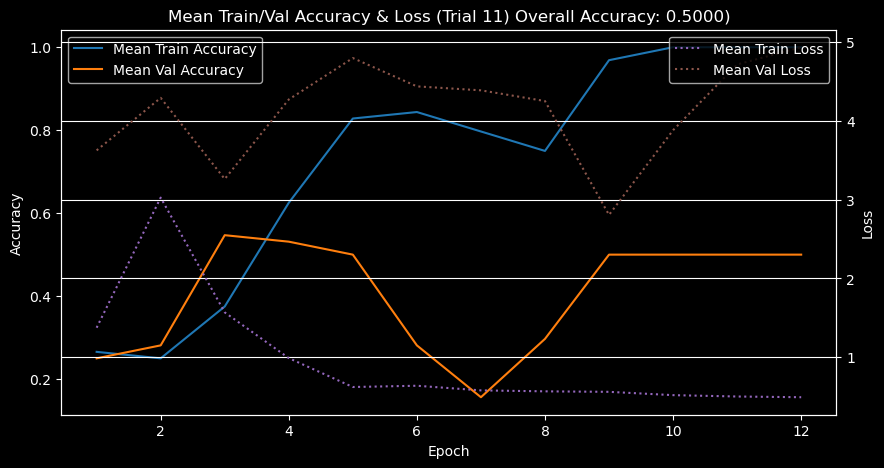

[I 2025-05-29 21:34:21,591] Trial 10 finished with value: 0.328125 and parameters: {'window_size': 4, 'mesh_rows_index': 1, 'conv1_filters': 32, 'conv2_filters': 128, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 1, 'padding3': 0, 'conv1_activation': 'elu', 'conv2_activation': 'gelu', 'conv3_activation': 'relu', 'dense_nodes': 256, 'dense_activation': 'leaky_relu', 'depth': 248, 'lstm1_cells': 32, 'lstm2_cells': 256, 'dense3_nodes': 64, 'dense3_activation': 'elu', 'learning_rate': 0.004388540855947588, 'batch_size': 32, 'dropout_rate': 0.05, 'optimizer': 'rmsprop', 'weight_decay': 9.950916717316215e-06, 'label_smoothing': 0.0, 'transformer_nhead': 8, 'transformer_layers': 1}. Best is trial 2 with value: 0.640625.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, flo

Trial: 12, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 7 epochs (no val_loss improvement).


Trial: 12, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 7 epochs (no val_loss improvement).


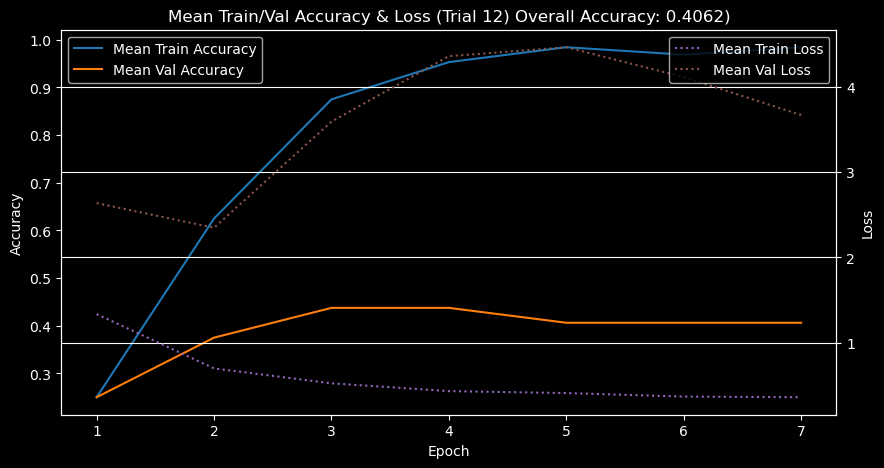

[I 2025-05-29 21:34:28,305] Trial 11 finished with value: 0.375 and parameters: {'window_size': 4, 'mesh_rows_index': 0, 'conv1_filters': 16, 'conv2_filters': 32, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (7, 7), 'conv3_kernel_shape': (5, 5), 'padding1': 0, 'padding2': 2, 'padding3': 1, 'conv1_activation': 'elu', 'conv2_activation': 'elu', 'conv3_activation': 'leaky_relu', 'dense_nodes': 64, 'dense_activation': 'gelu', 'depth': 248, 'lstm1_cells': 32, 'lstm2_cells': 256, 'dense3_nodes': 64, 'dense3_activation': 'gelu', 'learning_rate': 0.0035039494683970288, 'batch_size': 16, 'dropout_rate': 0.15000000000000002, 'optimizer': 'rmsprop', 'weight_decay': 2.1269034134778194e-05, 'label_smoothing': 0.0, 'transformer_nhead': 2, 'transformer_layers': 1}. Best is trial 2 with value: 0.640625.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bo

Trial: 13, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 7 epochs (no val_loss improvement).


Trial: 13, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 9 epochs (no val_loss improvement).


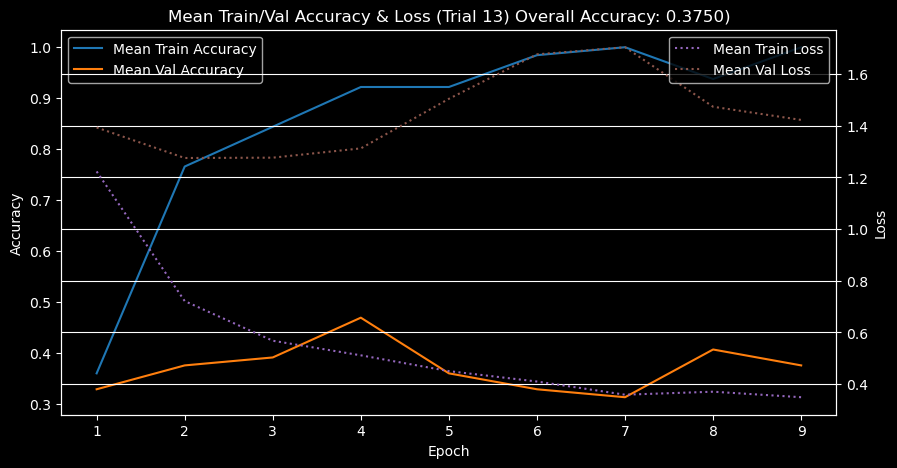

[I 2025-05-29 21:34:38,875] Trial 12 finished with value: 0.4375 and parameters: {'window_size': 4, 'mesh_rows_index': 0, 'conv1_filters': 16, 'conv2_filters': 256, 'conv3_filters': 256, 'conv1_kernel_shape': (7, 7), 'conv2_kernel_shape': (7, 7), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 1, 'padding3': 3, 'conv1_activation': 'elu', 'conv2_activation': 'gelu', 'conv3_activation': 'leaky_relu', 'dense_nodes': 64, 'dense_activation': 'leaky_relu', 'depth': 248, 'lstm1_cells': 32, 'lstm2_cells': 256, 'dense3_nodes': 32, 'dense3_activation': 'gelu', 'learning_rate': 0.00016700363936205856, 'batch_size': 8, 'dropout_rate': 0.1, 'optimizer': 'adamw', 'weight_decay': 0.009839559880362206, 'label_smoothing': 0.0, 'transformer_nhead': 2, 'transformer_layers': 1}. Best is trial 2 with value: 0.640625.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, fl

Trial: 14, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 21 epochs (no val_loss improvement).


Trial: 14, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 21 epochs (no val_loss improvement).


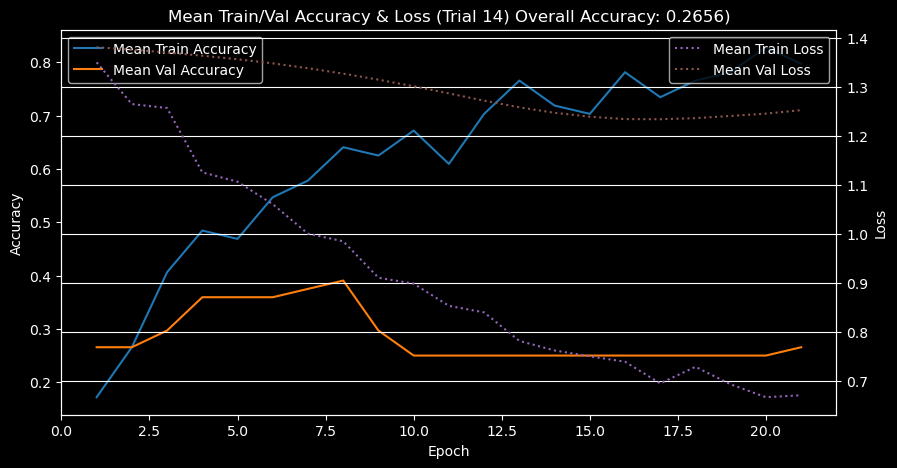

[I 2025-05-29 21:35:02,562] Trial 13 finished with value: 0.25 and parameters: {'window_size': 4, 'mesh_rows_index': 1, 'conv1_filters': 16, 'conv2_filters': 128, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (7, 7), 'conv3_kernel_shape': (5, 5), 'padding1': 1, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'elu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 64, 'dense_activation': 'gelu', 'depth': 248, 'lstm1_cells': 32, 'lstm2_cells': 256, 'dense3_nodes': 256, 'dense3_activation': 'gelu', 'learning_rate': 1.2355394909876286e-05, 'batch_size': 16, 'dropout_rate': 0.25, 'optimizer': 'rmsprop', 'weight_decay': 5.7421068589128285e-06, 'label_smoothing': 0.15000000000000002, 'transformer_nhead': 2, 'transformer_layers': 1}. Best is trial 2 with value: 0.640625.
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None

Trial: 15, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 19 epochs (no val_loss improvement).


Trial: 15, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 6 epochs (no val_loss improvement).


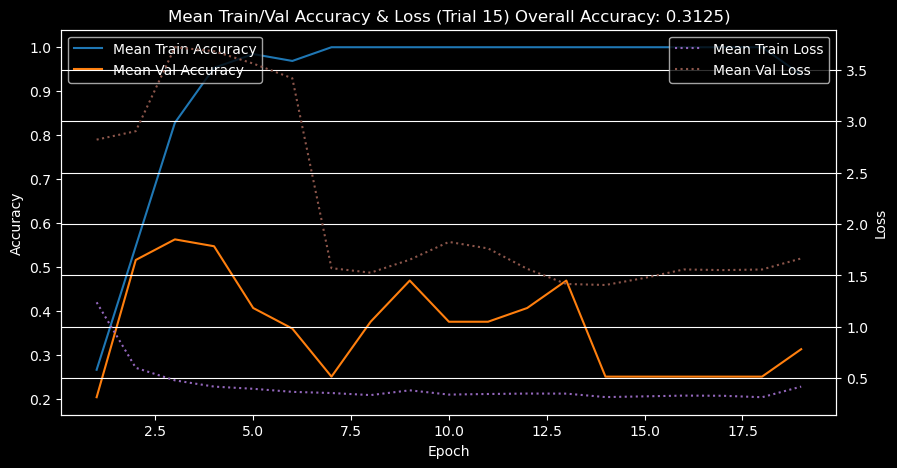

[I 2025-05-29 21:35:18,901] Trial 14 finished with value: 0.1875 and parameters: {'window_size': 4, 'mesh_rows_index': 0, 'conv1_filters': 16, 'conv2_filters': 128, 'conv3_filters': 256, 'conv1_kernel_shape': (7, 7), 'conv2_kernel_shape': (7, 7), 'conv3_kernel_shape': (7, 7), 'padding1': 2, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'elu', 'conv2_activation': 'relu', 'conv3_activation': 'relu', 'dense_nodes': 64, 'dense_activation': 'leaky_relu', 'depth': 248, 'lstm1_cells': 32, 'lstm2_cells': 64, 'dense3_nodes': 32, 'dense3_activation': 'gelu', 'learning_rate': 0.002163991484353648, 'batch_size': 16, 'dropout_rate': 0.15000000000000002, 'optimizer': 'adam', 'weight_decay': 0.00012448164226506718, 'label_smoothing': 0.0, 'transformer_nhead': 2, 'transformer_layers': 1}. Best is trial 2 with value: 0.640625.


In [10]:
import optuna
import json

number_of_trials = 15 # Number of trials for Optuna
number_of_folds = 2  # Number of folds for cross-validation

# Prepare a global DataFrame for metrics
all_metrics_df = utils.create_metrics_df()


# Define a wrapper so Optuna only gets the accuracy
def optuna_objective(trial):
    global all_metrics_df

    plot_path = f"{output_dir}/{which_dataset}/optuna_plots_{model_name}_trial_{trial.number}_timestamp_{timestamp}.png"

    best_val_acc, updated_metrics_df = utils.objective(
        trial, all_metrics_df, train_data, train_df, device,
        n_splits=number_of_folds, best_model_path=model_pth_path, plot_path=plot_path
    )
    all_metrics_df = updated_metrics_df  # update global after each trial
    return best_val_acc  # maximize accuracy

# Run Optuna and save best model after all trials
study = optuna.create_study(direction="maximize")
study.optimize(optuna_objective, n_trials=number_of_trials)

### Training stage #2 train on full train dataset with best paramters chosen

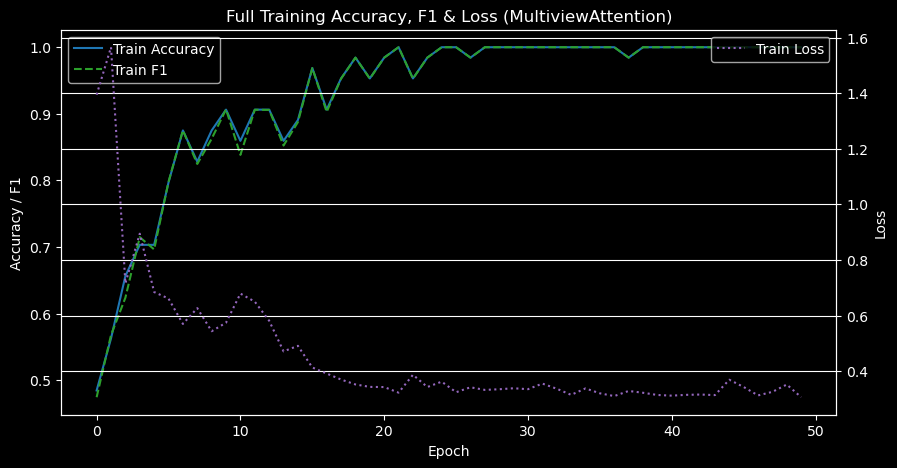

In [11]:
### train the best model on the full training set
# Save best model after all trials
best_trial = study.best_trial
best_params = best_trial.params
best_params["number_channels"] = train_data.shape[1]
best_params["number_classes"] = len(np.unique(train_df['task_type']))

best_params = best_trial.params.copy()
# Recompute split_size and mesh_columns if missing
if "split_size" not in best_params:
    T = train_data.shape[2]
    best_params["split_size"] = T // best_params["window_size"] 

if "mesh_rows" not in best_params and "mesh_rows_index" in best_params:
    # If mesh_rows_index is provided, use it to determine mesh_rows
    mesh_row_candidates = [r for r in range(5, min(50, best_params["split_size"] + 1)) if best_params["split_size"] % r == 0]
    best_params["mesh_rows"] = mesh_row_candidates[best_params["mesh_rows_index"]]

if "mesh_columns" not in best_params:
    best_params["mesh_columns"] = best_params["split_size"] // best_params["mesh_rows"]

# best_model = MEGClassifier(**{k: v for k, v in best_params.items() if k in MEGClassifier.__init__.__code__.co_varnames}).to(device)
best_model = utils.ModelClass(**{k: v for k, v in best_params.items() if k in utils.ModelClass.__init__.__code__.co_varnames}).to(device)


# Choose the correct dataloader and parameters for the model
if utils.ModelClass == MultiviewAttention:
    train_loader = utils.get_multiview_dataloader(
        train_data, train_df,
        batch_size=best_params["batch_size"],
        window_size=best_params["window_size"],
        mesh_rows=best_params["mesh_rows"],
        mesh_columns=best_params["mesh_columns"],
        depth=best_params["depth"],
        shuffle=True
    )
else:
    train_loader, train_X, train_y = utils.get_dataloader(
        data_tensor=train_data, df=train_df,
        batch_size=best_params["batch_size"],
        input_time_length=best_params.get("input_time_length", 256),
        stride=best_params.get("stride", 256),
        shuffle=True
    )

optimizer, scheduler, criterion = utils.get_training_parts(best_model, lr=best_params['learning_rate'])
epochs = 50
train_accs, train_f1s, train_losses = [], [], []

for epoch in range(epochs):
    train_preds, train_targets, train_loss = utils.single_train_epoch(
        model=best_model, 
        train_loader=train_loader,
        optimizer=optimizer,
        criterion=criterion,
        device=device
    )
    # Compute metrics for this epoch
    train_metrics = best_model.evaluate(y_true=train_targets, y_pred=train_preds)
    train_accs.append(train_metrics["overall_accuracy"])
    train_f1s.append(train_metrics["overall_F1"])
    train_losses.append(train_loss)
    scheduler.step()  # If using a scheduler

# Plot training curves
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(train_accs, label="Train Accuracy", color='tab:blue')
ax1.plot(train_f1s, label="Train F1", linestyle="--", color='tab:green')
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy / F1")
ax1.tick_params(axis='y')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(train_losses, label="Train Loss", linestyle=":", color='tab:purple')
ax2.set_ylabel("Loss")
ax2.tick_params(axis='y')
ax2.legend(loc='upper right')

plt.title(f"Full Training Accuracy, F1 & Loss ({utils.ModelClass.__name__})")
plt.grid(True)
plt.show()

### Training stage #3 saving the final model

In [12]:
# Create the model with the best hyperparameters
torch.save(best_model.state_dict(), model_pth_path)
print(f"Best model saved to {model_pth_path}")

# Save the best hyperparameters to a JSON file
with open(model_json_path, "w") as json_file:
    json.dump(best_params, json_file, indent=4)
print(f"Best hyperparameters saved to {model_json_path}")

Best model saved to ./Models/cross/best_model_MultiviewAttention_cross_20250529_213144.pth
Best hyperparameters saved to ./Models/cross/best_model_MultiviewAttention_cross_20250529_213144.json


### Evulate model and save logs

In [13]:
# evulate the best model on the test set
test_csv_path = f"{output_dir}/{which_dataset}/test_metrics_{model_name}_{timestamp}.csv"


test_metrics, df_test_result = utils.evaluate_model_on_testset(
    best_model, test_data, test_df, device,
    batch_size=best_params.get("batch_size", 64),
    input_time_length=best_params.get("input_time_length", 256),
    stride=best_params.get("stride", 256),
    path=test_csv_path
)

print("Test metrics:", test_metrics, "\nBest trial ID:", best_trial.number + 1, '\n')

# Add "test_" prefix to all columns in test_metrics
test_metrics_prefixed = {f"test_{k}": v for k, v in test_metrics.items()}

# Find the row for the best trial (trial_id matches best_trial.number + 1)
row_idx = all_metrics_df[all_metrics_df["trial_id"] == best_trial.number + 1].index
if len(row_idx) == 0:
    # fallback: use last row
    row_idx = [all_metrics_df.index[-1]]
row_idx = row_idx[0]

# Copy all columns in test_metrics_prefixed to the DataFrame row
for col, value in test_metrics_prefixed.items():
    if col in all_metrics_df.columns:
        all_metrics_df.at[row_idx, col] = value
            
# Save metrics
all_metrics_df.to_csv(model_csv_path, index=False)
print(f"All metrics saved to {model_csv_path}")
print("Best hyperparameters:", best_params)
print("Best validation accuracy:", study.best_value)

Test metrics: {'overall_accuracy': 0.75, 'overall_F1': 0.7453379953379953, 'overall_recall': 0.75, 'overall_precision': 0.7452380952380953, 'resting_accuracy': 1.0, 'resting_F1': 1.0, 'resting_recall': 1.0, 'resting_precision': 1.0, 'math_accuracy': 0.8333333333333334, 'math_F1': 0.45454545454545453, 'math_recall': 0.4166666666666667, 'math_precision': 0.5, 'memory_accuracy': 0.5, 'memory_F1': 0.2222222222222222, 'memory_recall': 0.16666666666666666, 'memory_precision': 0.3333333333333333, 'motor_accuracy': 0.6666666666666666, 'motor_F1': 0.4, 'motor_recall': 0.3333333333333333, 'motor_precision': 0.5} 
Best trial ID: 3 

All metrics saved to ./Output/cross/best_model_MultiviewAttention_cross_20250529_213144.csv
Best hyperparameters: {'window_size': 4, 'mesh_rows_index': 1, 'conv1_filters': 16, 'conv2_filters': 128, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (7, 7), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 1, 'padding3': 2, 'conv1_activati

C:\Users\bar24\AppData\Local\Temp\ipykernel_6804\2860861484.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  overall_acc_per_task = df_test_result.groupby('y_true').apply(lambda x: (x['y_true'] == x['y_pred']).mean())
C:\Users\bar24\AppData\Local\Temp\ipykernel_6804\2860861484.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_patient_acc = df_test_result.groupby(['patient_id', 'y_true']).apply(lam

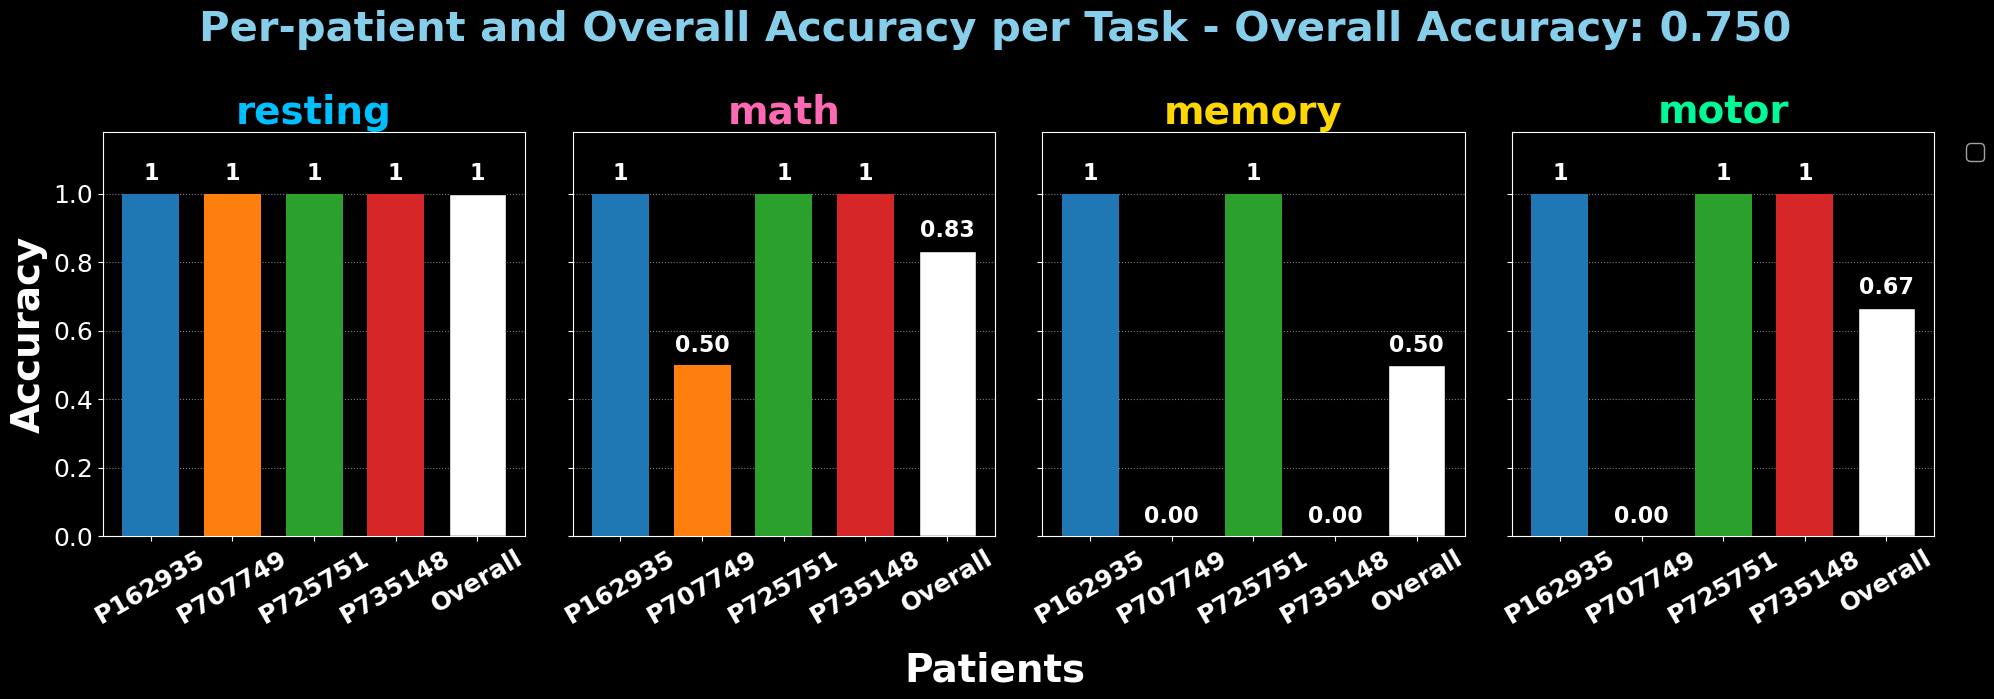

In [14]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('dark_background')

task_names = ["resting", "math", "memory", "motor"]

# Compute overall accuracy per task
overall_acc_per_task = df_test_result.groupby('y_true').apply(lambda x: (x['y_true'] == x['y_pred']).mean())
per_patient_acc = df_test_result.groupby(['patient_id', 'y_true']).apply(lambda x: (x['y_true'] == x['y_pred']).mean()).unstack(0)
overall_acc = (df_test_result['y_true'] == df_test_result['y_pred']).mean()

tasks = sorted(df_test_result['y_true'].unique())
patients = per_patient_acc.columns.tolist()
n_tasks = len(tasks)
n_bars = len(patients) + 1  # patients + overall

fig, axs = plt.subplots(1, n_tasks, figsize=(5*n_tasks, 7), sharey=True)

bar_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f']
overall_color = '#ffffff'
# Distinct, readable colors for task titles (not same as bars)
task_title_colors = ['#00bfff', '#ff69b4', '#ffd700', '#00fa9a']  # blue, pink, gold, green

for t_idx, t in enumerate(tasks):
    ax = axs[t_idx]
    # Per-patient bars
    for i, patient in enumerate(patients):
        acc = per_patient_acc[patient].reindex(tasks, fill_value=0)[t]
        bar = ax.bar(i, acc, color=bar_colors[i % len(bar_colors)], width=0.7, label=f'Patient {patient}' if t_idx == 0 else "", zorder=3)
        label = str(int(acc)) if np.isclose(acc, 1.0) else f"{acc:.2f}"
        ax.text(i, acc + 0.025, label, ha='center', va='bottom', fontsize=16, color='white', fontweight='bold')
    # Overall bar
    overall = overall_acc_per_task.reindex(tasks, fill_value=0)[t]
    bar = ax.bar(len(patients), overall, color=overall_color, edgecolor='black', width=0.7, label='Overall' if t_idx == 0 else "", zorder=3)
    label = str(int(overall)) if np.isclose(overall, 1.0) else f"{overall:.2f}"
    ax.text(len(patients), overall + 0.025, label, ha='center', va='bottom', fontsize=16, color='white', fontweight='bold')
    # Formatting
    ax.set_title(task_names[t], fontsize=28, fontweight='bold', color=task_title_colors[t_idx % len(task_title_colors)])
    ax.set_xticks(list(range(n_bars)))
    ax.set_xticklabels([f"P{p}" for p in patients] + ["Overall"], fontsize=18, fontweight='bold', rotation=30)
    ax.set_ylim(0, 1.18)
    ax.grid(axis='y', linestyle=':', alpha=0.5, zorder=0)
    ax.tick_params(axis='y', labelsize=18)
    if t_idx == 0:
        ax.set_ylabel('Accuracy', fontsize=28, fontweight='bold', color='white')

    if t_idx == n_tasks-1:
        ax.legend(fontsize=16, loc='upper left', bbox_to_anchor=(1.05, 1.0))

fig.supxlabel('Patients', fontsize=28, fontweight='bold', color='white')  # Centered x-axis label
fig.suptitle(f'Per-patient and Overall Accuracy per Task - Overall Accuracy: {overall_acc:.3f}', fontsize=30, fontweight='bold', color='skyblue')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

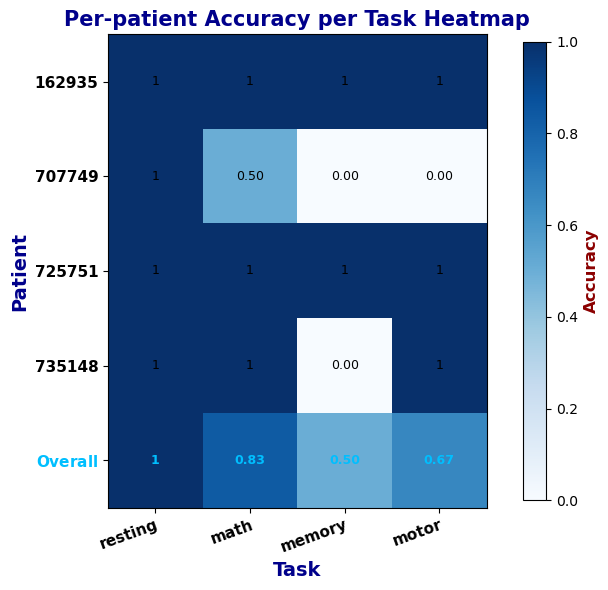

In [15]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('default')

task_names = ["resting", "math", "memory", "motor"]

tasks = sorted(df_test_result['y_true'].unique())
patients = per_patient_acc.columns.tolist()
heatmap_data = per_patient_acc.reindex(index=tasks, columns=patients, fill_value=np.nan).T.values  # (n_patients, n_tasks)
overall_per_task = overall_acc_per_task.reindex(tasks, fill_value=np.nan).values  # (n_tasks,)

# Add overall_per_task as a new row at the end
heatmap_data_with_overall = np.vstack([heatmap_data, overall_per_task[None, :]])
yticklabels = [str(p) for p in patients] + [r"$\bf{Overall}$"]  # bold and pretty overall label

fig, ax = plt.subplots(figsize=(10, max(6, len(yticklabels)*0.5)))

im = ax.imshow(heatmap_data_with_overall, cmap='Blues', vmin=0, vmax=1)

# Show all ticks and label them
ax.set_xticks(np.arange(len(tasks)))
ax.set_yticks(np.arange(len(yticklabels)))
ax.set_xticklabels([task_names[t] for t in tasks], fontsize=11, fontweight='bold')
ax.set_yticklabels(yticklabels, fontsize=11, fontweight='bold')

plt.setp(ax.get_xticklabels(), rotation=20, ha="right", rotation_mode="anchor")

# Color only the last yticklabel ("Overall") in darkred
for tick in ax.get_yticklabels():
    tick.set_color("black")
ax.get_yticklabels()[-1].set_color("deepskyblue")

# Loop over data dimensions and create text annotations.
for i in range(len(yticklabels)):
    for j in range(len(tasks)):
        val = heatmap_data_with_overall[i, j]
        if not np.isnan(val):
            label = str(int(val)) if np.isclose(val, 1.0) else f"{val:.2f}"
            # Make "Overall" row text bold and darkred, others normal black
            if i == len(yticklabels)-1:
                color = "deepskyblue"
                weight = 'bold'
            else:
                color = "black"
                weight = 'normal'
            ax.text(j, i, label, ha="center", va="center", color=color, fontsize=9, fontweight=weight)

ax.set_xlabel("Task", fontsize=14, fontweight='bold', color="darkblue")
ax.set_ylabel("Patient", fontsize=14, fontweight='bold', color="darkblue")
ax.set_title("Per-patient Accuracy per Task Heatmap", color="darkblue", fontsize=15, fontweight='bold')
# Make colorbar shorter (smaller height)
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.04)
cbar.set_label('Accuracy', fontsize=12, fontweight="bold", color="darkred")
plt.tight_layout()
plt.show()

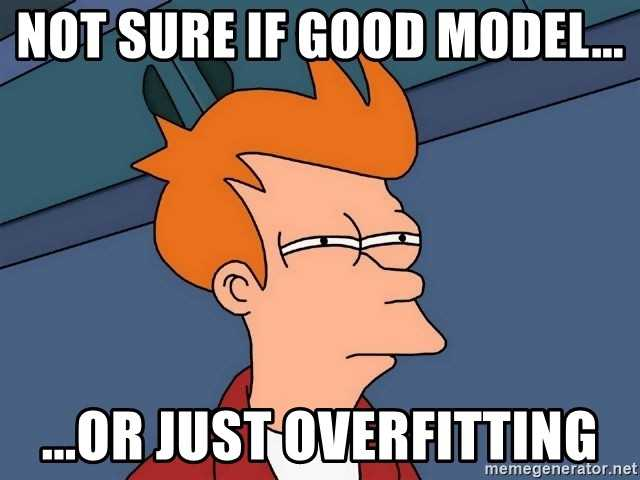

In [16]:
from IPython.display import Image, display

display(Image(filename="overfitunsurefry.webp"))

### Display first few lines from logs

In [17]:
from IPython.display import display, HTML

# Show the first 10 rows of the DataFrame in a scrollable box
display(HTML(all_metrics_df.head(10).to_html(max_rows=10, max_cols=100, notebook=True, show_dimensions=True, justify='center', border=1, table_id="scroll_df")))

,trial_id,epoch,train_overall_accuracy,train_overall_F1,train_overall_recall,train_overall_precision,train_resting_accuracy,train_resting_F1,train_resting_recall,train_resting_precision,train_math_accuracy,train_math_F1,train_math_recall,train_math_precision,train_memory_accuracy,train_memory_F1,train_memory_recall,train_memory_precision,train_motor_accuracy,train_motor_F1,train_motor_recall,train_motor_precision,val_overall_accuracy,val_overall_F1,val_overall_recall,val_overall_precision,val_resting_accuracy,val_resting_F1,val_resting_recall,val_resting_precision,val_math_accuracy,val_math_F1,val_math_recall,val_math_precision,val_memory_accuracy,val_memory_F1,val_memory_recall,val_memory_precision,val_motor_accuracy,val_motor_F1,val_motor_recall,val_motor_precision,test_overall_accuracy,test_overall_F1,test_overall_recall,test_overall_precision,test_resting_accuracy,test_resting_F1,test_resting_recall,test_resting_precision,test_math_accuracy,test_math_F1,test_math_recall,test_math_precision,test_memory_accuracy,test_memory_F1,test_memory_recall,test_memory_precision,test_motor_accuracy,test_motor_F1,test_motor_recall,test_motor_precision,window_size,conv1_filters,conv2_filters,conv3_filters,conv1_kernel_shape,conv2_kernel_shape,conv3_kernel_shape,padding1,padding2,padding3,conv1_activation,conv2_activation,conv3_activation,dense_nodes,dense_activation,depth,lstm1_cells,lstm2_cells,dense3_nodes,dense3_activation,number_classes,number_channels,mesh_rows,mesh_columns,split_size,learning_rate,batch_size,dropout_rate,fold_index,optimizer,weight_decay,label_smoothing,transformer_nhead,transformer_layers,train_loss,val_loss
0,1,1,0.31250,0.285714,0.31250,0.333333,0.375,0.181818,0.1250,0.333333,0.000,0.000000,0.0000,0.0,0.625,0.384615,0.3125,0.5,0.250,0.133333,0.083333,0.333333,0.25000,0.100000,0.25000,0.062500,0.0,0.0,0.0,0.0,0.000,0.000000,0.0000,0.0,1.000,1.000000,1.0000,1.0,0.000,0.000000,0.0000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16,16,256,64,"(3, 3)","(5, 5)","(7, 7)",2,2,3,relu,relu,leaky_relu,128,elu,248,256,256,128,gelu,4,248,13,19,247,0.00083,64,0.2,1.0,rmsprop,0.003096,0.05,2.0,1.0,1.271856,1.076822
1,1,2,0.78125,0.729469,0.78125,0.883333,1.000,1.000000,1.0000,1.000000,1.000,1.000000,1.0000,1.0,1.000,1.000000,1.0000,1.0,0.125,0.111111,0.062500,0.500000,0.25000,0.100000,0.25000,0.062500,0.0,0.0,0.0,0.0,0.000,0.000000,0.0000,0.0,1.000,1.000000,1.0000,1.0,0.000,0.000000,0.0000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16,16,256,64,"(3, 3)","(5, 5)","(7, 7)",2,2,3,relu,relu,leaky_relu,128,elu,248,256,256,128,gelu,4,248,13,19,247,0.00083,64,0.2,1.0,rmsprop,0.003096,0.05,2.0,1.0,0.551273,1.120605
2,1,3,0.71875,0.665977,0.71875,0.833333,0.125,0.111111,0.0625,0.500000,0.750,0.428571,0.3750,0.5,1.000,1.000000,1.0000,1.0,1.000,1.000000,1.000000,1.000000,0.25000,0.100000,0.25000,0.062500,0.0,0.0,0.0,0.0,0.000,0.000000,0.0000,0.0,1.000,1.000000,1.0000,1.0,0.000,0.000000,0.0000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16,16,256,64,"(3, 3)","(5, 5)","(7, 7)",2,2,3,relu,relu,leaky_relu,128,elu,248,256,256,128,gelu,4,248,13,19,247,0.00083,64,0.2,1.0,rmsprop,0.003096,0.05,2.0,1.0,0.536057,1.025293
3,1,4,1.00000,1.000000,1.00000,1.000000,1.000,1.000000,1.0000,1.000000,1.000,1.000000,1.0000,1.0,1.000,1.000000,1.0000,1.0,1.000,1.000000,1.000000,1.000000,0.09375,0.042857,0.09375,0.027778,0.0,0.0,0.0,0.0,0.000,0.000000,0.0000,0.0,0.375,0.272727,0.1875,0.5,0.000,0.000000,0.0000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16,16,256,64,"(3, 3)","(5, 5)","(7, 7)",2,2,3,relu,relu,leaky_relu,128,elu,248,256,256,128,gelu,4,248,13,19,247,0.00083,64,0.2,1.0,rmsprop,0.003096,0.05,2.0,1.0,0.413117,1.112157
4,1,5,0.93750,0.934874,0.93750,0.944444,1.000,1.000000,1.0000,1.000000,1.000,1.000000,1.0000,1.0,1.000,1.000000,1.0000,1.0,0.750,0.285714,0.250000,0.333333,0.18750,0.136364,0.18750

### Reload the best model!

In [18]:
import json
from Model import MultiviewAttention

timestamp = "20250528_231723"
json_path = f"{model_dir}/{which_dataset}/best_model_{MODEL_NAME}_{which_dataset}_{timestamp}.json"

with open(json_path) as f:
    params = json.load(f)


model = MultiviewAttention(**{k: v for k, v in params.items() if k in MultiviewAttention.__init__.__code__.co_varnames})

### Plot plots

In [19]:
print("we are done, goodbye!")

we are done, goodbye!
